# Quiz 3 · Análisis de una serie de tiempo financiera

**Estudiante:** Lina Paola Alarcon Arboleda
**Ticker asignado:** EURUSD=X  
**Activo analizado:** EURUSD
**Periodo de análisis:** FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-10-01"
## Propósito
Analizar el comportamiento histórico de una serie de tiempo financiera mediante visualización, rendimientos, volatilidad y una proyección de corto plazo.

> Este análisis tiene fines académicos y no constituye una recomendación de inversión.

## 0. Configuración
Escriba su ticker exactamente como aparece en S22. No lo cambie: la entrega se revisa contra el ticker asignado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKER = "EURUSD=X"
FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-10-01"

## 1. Contexto del activo
El ticker EURUSD=X representa la tasa de cambio entre el euro (EUR) y el dólar estadounidense (USD). Este par de divisas se negocia en el mercado internacional de divisas, conocido como Forex. Su cotización nos dice cuántos dólares estadounidenses se necesitan para comprar un euro. Por ejemplo, si la tasa es de 1,10, eso significa que un euro equivale a 1,10 dólares.

Analizar este activo es crucial porque nos permite ver cómo varía el valor del euro frente al dólar con el tiempo. Estas fluctuaciones pueden tener un impacto significativo en el comercio internacional, las inversiones y las operaciones financieras. Al estudiar sus precios históricos, podemos identificar tendencias, medir las variaciones diarias y evaluar el nivel de volatilidad del tipo de cambio.

Fuente bibliográfica
- Yahoo Finance. EUR/USD (EURUSD=X). https://finance.yahoo.com/quote/EURUSD%3DX/
- atfx.com
https://www.atfx.com/es/analisis/estrategias-de-trading/que-es-el-eurusd

## 2. Descarga de datos
Descargue al menos dos años de precios diarios.

In [2]:
# Completa aquí: descarga la serie con yf.download y guárdala en la variable datos
datos = yf.download(
    TICKER,
    start=FECHA_INICIO,
    end=FECHA_FIN,
    auto_adjust=True,
    progress=False
)

if isinstance(datos.columns, pd.MultiIndex):
    datos.columns = datos.columns.get_level_values(0)

datos = datos.dropna(how="all")

# Muestra las primeras y últimas observaciones

print("Primeras observaciones:")
display(datos.head())

print("Últimas observaciones:")
display(datos.tail())



Primeras observaciones:


Price,Close,High,Low,Open,Volume
Date,,,,,
2024-01-01,1.105583,1.105339,1.103997,1.105583,0
2024-01-02,1.103875,1.104606,1.094200,1.103875,0
2024-01-03,1.094176,1.096700,1.089871,1.094176,0
2024-01-04,1.092777,1.097021,1.091703,1.092777,0
2024-01-05,1.094739,1.099638,1.087985,1.094739,0


Últimas observaciones:


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-09-24,1.138187,1.139991,1.136041,1.138291,0
2026-09-25,1.137475,1.141162,1.136868,1.137359,0
2026-09-28,1.137799,1.139212,1.135435,1.137825,0
2026-09-29,1.137268,1.137268,1.132824,1.137074,0
2026-09-30,1.134083,1.137773,1.132926,1.134044,0


## 3. Calidad de datos
Revise periodo real, frecuencia, número de observaciones, valores faltantes y duplicados.

In [3]:
# Completa aquí: número de filas, fechas mínima y máxima, faltantes y duplicados

print("Número de observaciones:", len(datos))
print("Fecha mínima:", datos.index.min())
print("Fecha máxima:", datos.index.max())
print("Frecuencia de los datos: diaria (días hábiles de mercado)")
print("Valores faltantes:", datos.isna().sum().sum())
print("Fechas duplicadas:", datos.index.duplicated().sum())


Número de observaciones: 713
Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2026-09-30 00:00:00
Frecuencia de los datos: diaria (días hábiles de mercado)
Valores faltantes: 0
Fechas duplicadas: 0


**Interpretación:** indique las decisiones de limpieza aplicadas.

Se revisaron un total de 713 observaciones desde el 1 de enero de 2024 hasta el 30 de septiembre de 2026. Los datos están completos, sin valores faltantes ni fechas duplicadas, así que no hubo necesidad de eliminar ningún registro extra. Se mantuvieron los datos descargados para seguir adelante con el análisis.


## 4. Serie de precios
Grafique el precio de cierre en el tiempo, con título, ejes y fuente.

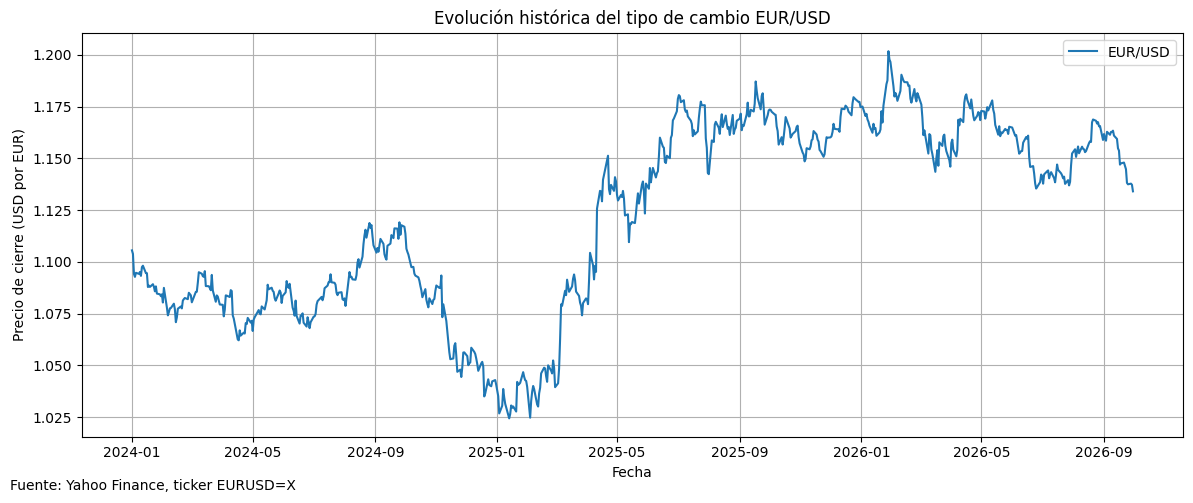

In [4]:
# Completa aquí: gráfico del precio de cierre

plt.figure(figsize=(12, 5))
plt.plot(datos.index, datos["Close"], label="EUR/USD")

plt.title("Evolución histórica del tipo de cambio EUR/USD")
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre (USD por EUR)")
plt.legend()
plt.grid(True)

plt.figtext(0.01, 0.01, "Fuente: Yahoo Finance, ticker EURUSD=X")
plt.tight_layout()
plt.show()


## 5. Lectura temporal
Describa tendencia, máximos, mínimos y cambios relevantes que observa en el gráfico.

Entre 2024 y septiembre de 2026, la tasa de cambio experimentó varios cambios. Al inicio de 2024, se mantuvo en cerca a 1,08 dolares por euro. A principios de 2025, llegó a su punto más bajo, cerca de 1,03, pero luego comenzó a subir en los meses siguientes. Su pico se registró a comienzos de 2026, alcanzando casi 1,20. Después de eso, el precio bajó y cerró el período alrededor de 1,14. En resumen, aunque hubo altibajos, se puede notar una tendencia general al alza desde 2025.

## 6. Rendimientos diarios
Calcule los rendimientos diarios, presente su resumen estadístico y grafíquelos.

Resumen estadístico de los rendimientos diarios:


,Close
count,712.000000
mean,0.000045
std,0.004218
min,-0.018418
25%,-0.002280
50%,-0.000319
75%,0.002337
max,0.027919


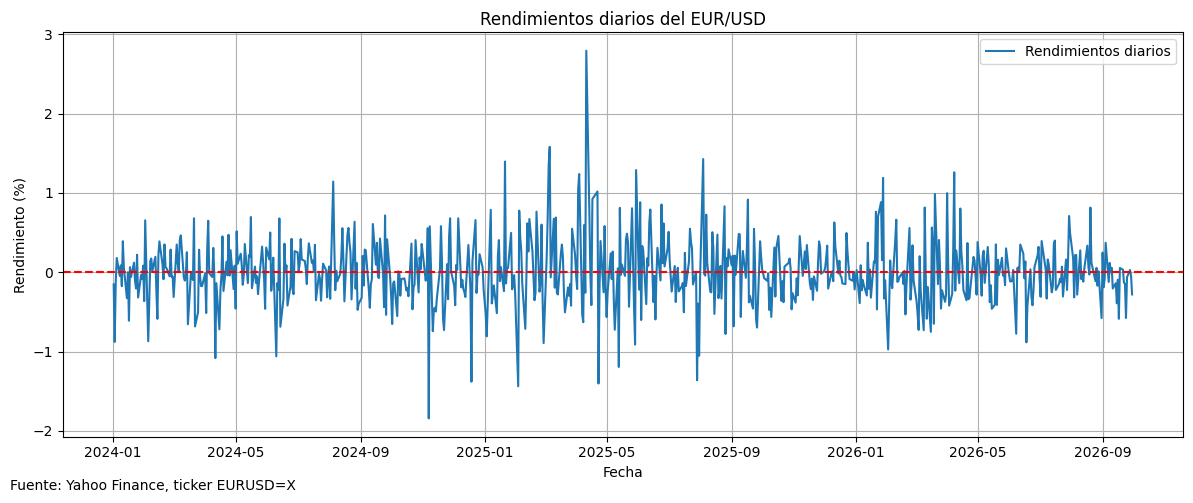

In [5]:
# Completa aquí: rendimientos = cierre.pct_change()
# Precio de cierre
cierre = datos["Close"]

# Calcular los rendimientos diarios
rendimientos = cierre.pct_change().dropna()

# Resumen estadístico
print("Resumen estadístico de los rendimientos diarios:")
display(rendimientos.describe())

# Gráfico de rendimientos diarios
plt.figure(figsize=(12, 5))
plt.plot(rendimientos.index, rendimientos * 100,
         label="Rendimientos diarios")

plt.title("Rendimientos diarios del EUR/USD")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento (%)")
plt.axhline(0, color="red", linestyle="--")
plt.legend()
plt.grid(True)

plt.figtext(0.01, 0.01, "Fuente: Yahoo Finance, ticker EURUSD=X")
plt.tight_layout()
plt.show()

## 7. Volatilidad móvil
Calcule la volatilidad móvil de 20 días y grafíquela.

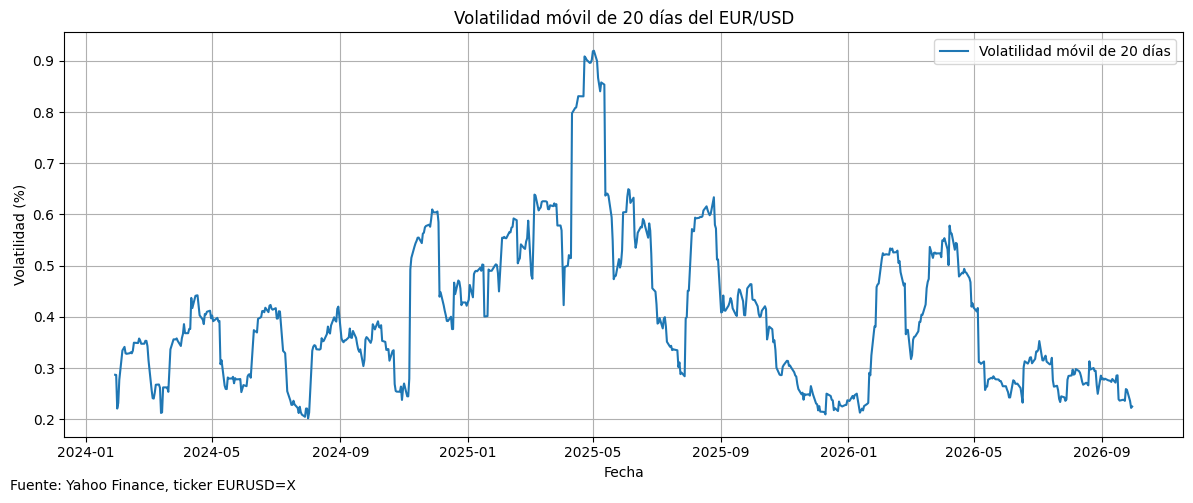

In [6]:
# Completa aquí: volatilidad = rendimientos.rolling(20).std()
# Calcular la volatilidad móvil de 20 días
volatilidad = rendimientos.rolling(20).std()

# Graficar la volatilidad móvil
plt.figure(figsize=(12, 5))
plt.plot(volatilidad.index, volatilidad * 100,
         label="Volatilidad móvil de 20 días")

plt.title("Volatilidad móvil de 20 días del EUR/USD")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad (%)")
plt.legend()
plt.grid(True)

plt.figtext(0.01, 0.01, "Fuente: Yahoo Finance, ticker EURUSD=X")
plt.tight_layout()
plt.show()

**Interpretación:** ¿en qué periodos se concentra la mayor variabilidad?

La mayor variabilidad se presentó entre marzo y mayo de 2025, con un pico superior al 0,9 %. También hubo alta volatilidad entre noviembre de 2024 y febrero de 2025.

## 8. Visualización complementaria
Construya una tercera visualización pertinente (promedio móvil, distribución de rendimientos, comparación mensual u otra) y justifique su elección.

Elegí esta gráfica porque permite identificar cuáles son las variaciones diarias más frecuentes y observar si hubo cambios extremos en el tipo de cambio.


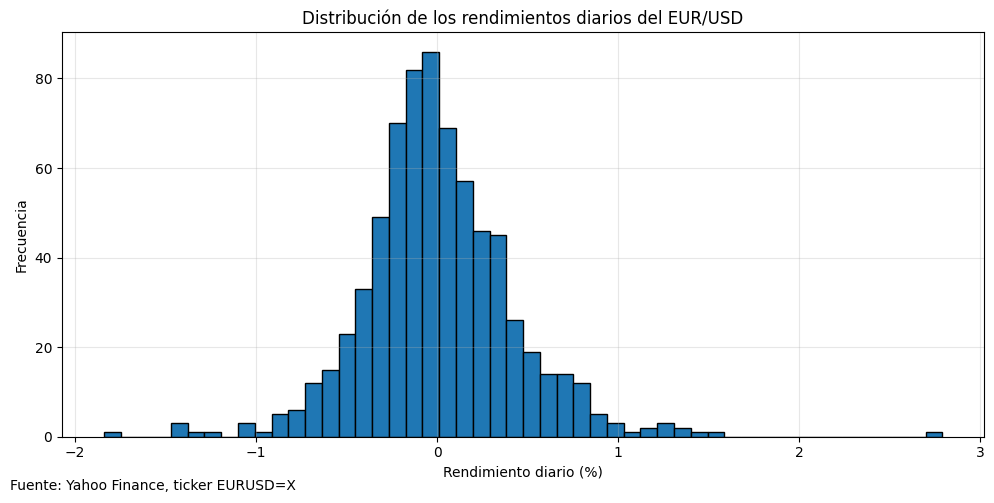

In [7]:
# Completa aquí

plt.figure(figsize=(10, 5))

plt.hist(rendimientos * 100, bins=50, edgecolor="black")

plt.title("Distribución de los rendimientos diarios del EUR/USD")
plt.xlabel("Rendimiento diario (%)")
plt.ylabel("Frecuencia")
plt.grid(True, alpha=0.3)

plt.figtext(0.01, 0.01, "Fuente: Yahoo Finance, ticker EURUSD=X")
plt.tight_layout()
plt.show()


## 9. Proyección corta
Plantee una proyección sencilla de corto plazo (por ejemplo, promedio móvil o regresión lineal) y explique sus limitaciones.

Las limitaciones de esta proyección son importantes. Se fundamenta en las tendencias observadas en los últimos 60 días, sin tener en cuenta noticias económicas, decisiones de bancos centrales ni otros elementos que puedan influir en el tipo de cambio. Por lo tanto, se trata de una estimación orientativa que no asegura los precios futuros.

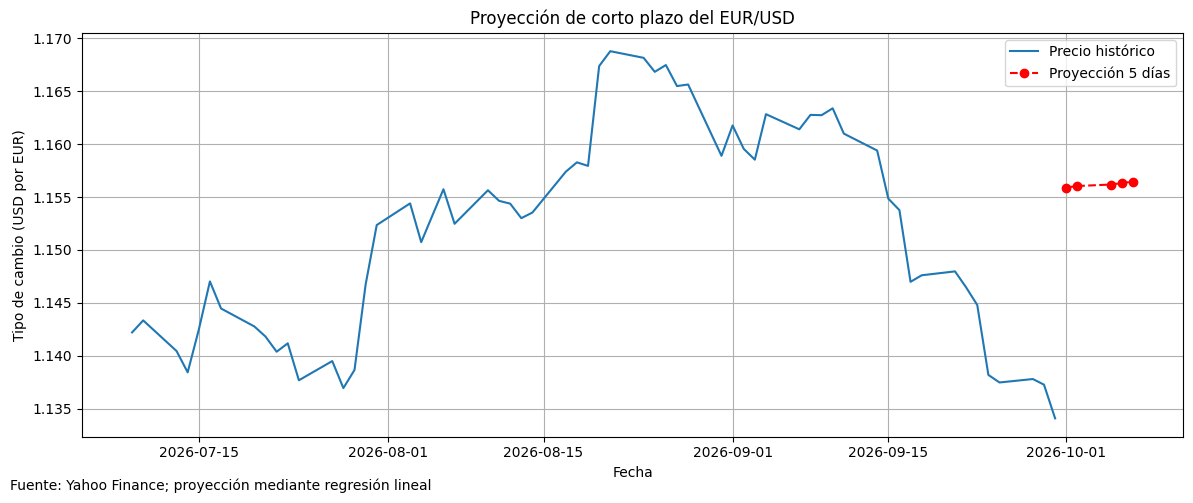

Precios proyectados:


,Fecha,Precio proyectado
0,2026-10-01,1.155900
1,2026-10-02,1.156041
2,2026-10-05,1.156181
3,2026-10-06,1.156321
4,2026-10-07,1.156462


In [8]:
# Completa aquí
from sklearn.linear_model import LinearRegression

# Usar los últimos 60 días de precios
ultimos = cierre.dropna().tail(60)
X = np.arange(len(ultimos)).reshape(-1, 1)
y = ultimos.values

# Ajustar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Proyectar los próximos 5 días
X_futuro = np.arange(len(ultimos), len(ultimos) + 5).reshape(-1, 1)
proyeccion = modelo.predict(X_futuro)

# Crear fechas futuras
fechas_futuras = pd.bdate_range(
    start=ultimos.index[-1] + pd.Timedelta(days=1),
    periods=5
)

# Graficar precios y proyección
plt.figure(figsize=(12, 5))
plt.plot(ultimos.index, y, label="Precio histórico")
plt.plot(fechas_futuras, proyeccion, "r--o", label="Proyección 5 días")

plt.title("Proyección de corto plazo del EUR/USD")
plt.xlabel("Fecha")
plt.ylabel("Tipo de cambio (USD por EUR)")
plt.legend()
plt.grid(True)

plt.figtext(0.01, 0.01, "Fuente: Yahoo Finance; proyección mediante regresión lineal")
plt.tight_layout()
plt.show()

print("Precios proyectados:")
display(pd.DataFrame({
    "Fecha": fechas_futuras,
    "Precio proyectado": proyeccion
}))

## 10. Conclusión financiera
Redacte tres conclusiones concretas sobre comportamiento, riesgo y límites del análisis.

1. El EUR/USD presentó varias subidas y bajadas entre 2024 y 2026, con un aumento importante durante 2025 y un máximo cercano a 1,20 en 2026.

2. El riesgo varió durante el período analizado, con mayores cambios diarios entre marzo y mayo de 2025.

3. La proyección permite estimar el comportamiento de los próximos días, pero no garantiza el resultado, porque el tipo de cambio depende de factores económicos y noticias que pueden cambiar su valor.


## 11. Video de sustentación
Pegue el enlace de su video individual (máximo 5 minutos). En el video explique su activo, sus gráficos y sus conclusiones.

https://youtu.be/sHWPegTSKrU